# TF Phosphosite Cluster Trajectory Panel

Trimmed subset of `sig_TFs_DEsites_cluster_dynamics_plot.ipynb`.

In [8]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import os
from scipy import stats
from matplotlib.lines import Line2D

from matplotlib.ticker import FormatStrFormatter, MaxNLocator

In [2]:
# directory and data file settings
psites_f = "/ix/djishnu/Aaron_F/proteomics_proj/Data/phosphoproteomics/TMT_control_centered_log2fc.csv"
cluster_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig1/des_heatmap/out_files/pairwise_DEsites_9_clusters_ordered.csv"

# sig_tf files:
tf1_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/DEG_motif_enrichment/common_degs_enr/sig_TF_results/out_files/sig_tomtom_TFs_withLabels.csv"
tf2_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/modisco/out_files/sig_modisco_TFs_withLabels.csv"
tf3_f = "/ix/djishnu/Aaron_F/proteomics_proj/Results/decoupler/out_files/sig_decoupler_TFs_withLabels.csv"

out_dir = "/ix/djishnu/Aaron_F/proteomics_proj/Results/Figures/Fig3/TFsite_cluster_dynamics"

os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/figures", exist_ok=True)
os.makedirs(f"{out_dir}/out_files", exist_ok=True)
os.chdir(out_dir)

In [3]:
# load prot. data
prot_df = pd.read_csv(psites_f, header=0)
print(prot_df.shape)

cluster_info = pd.read_csv(cluster_f)
print(cluster_info.head())

(21641, 16)
                              id  cluster geneSymbol cluster_color
0  P83741-3_S2282s_1_0_2280_2282        1       Wnk1       #f77189
1    E9PWW9_S1312s_1_1_1312_1312        1       Rsf1       #f77189
2       O09047_T456t_1_1_456_456        1      C3ar1       #f77189
3  O09047_T459tT462t_2_1_452_462        1      C3ar1       #f77189
4       Q3UZA1_S380s_1_0_378_380        1      Rcsd1       #f77189


In [4]:
# psites_f already has its own geneSymbol column -- drop it before
# merging so cluster_info's geneSymbol doesn't collide into
# geneSymbol_x/geneSymbol_y suffixes
if "geneSymbol" in prot_df.columns:
    prot_df = prot_df.drop(columns=["geneSymbol"])

prot_df = prot_df.merge(
    cluster_info[["id", "cluster", "geneSymbol", "cluster_color"]],
    left_on="id",
    right_on="id",
    how="inner"
)

prot_df = prot_df.set_index("id")

## Restrict to TF phosphosites (union across all three motif/activity methods)

In [5]:
# get TF genes:
tf1_df = pd.read_csv(tf1_f)
tf1_genes = tf1_df.loc[tf1_df.is_expressed,"tf_symbol"].tolist()

tf2_df = pd.read_csv(tf2_f)
tf2_genes = tf2_df.loc[tf2_df.is_expressed,"tf_symbol"].tolist()

tf3_df = pd.read_csv(tf3_f)
tf3_genes = tf3_df.loc[tf3_df.is_expressed,"tf_symbol"].tolist()

tf_genes = list(set(tf1_genes + tf2_genes + tf3_genes))
len(tf_genes)

244

In [6]:
prot_df = prot_df.loc[
    prot_df.geneSymbol.isin(tf_genes),
].copy()
prot_df.shape

(42, 17)

## Panel plot — one subplot per cluster, IL6 (dashed) vs IL10 (solid), mean ± SEM

Grid size (`nrows`/`ncols`) is computed dynamically from `len(clusters)`, so this scales automatically from 6 to 9 (or any other number of) clusters without any code changes.

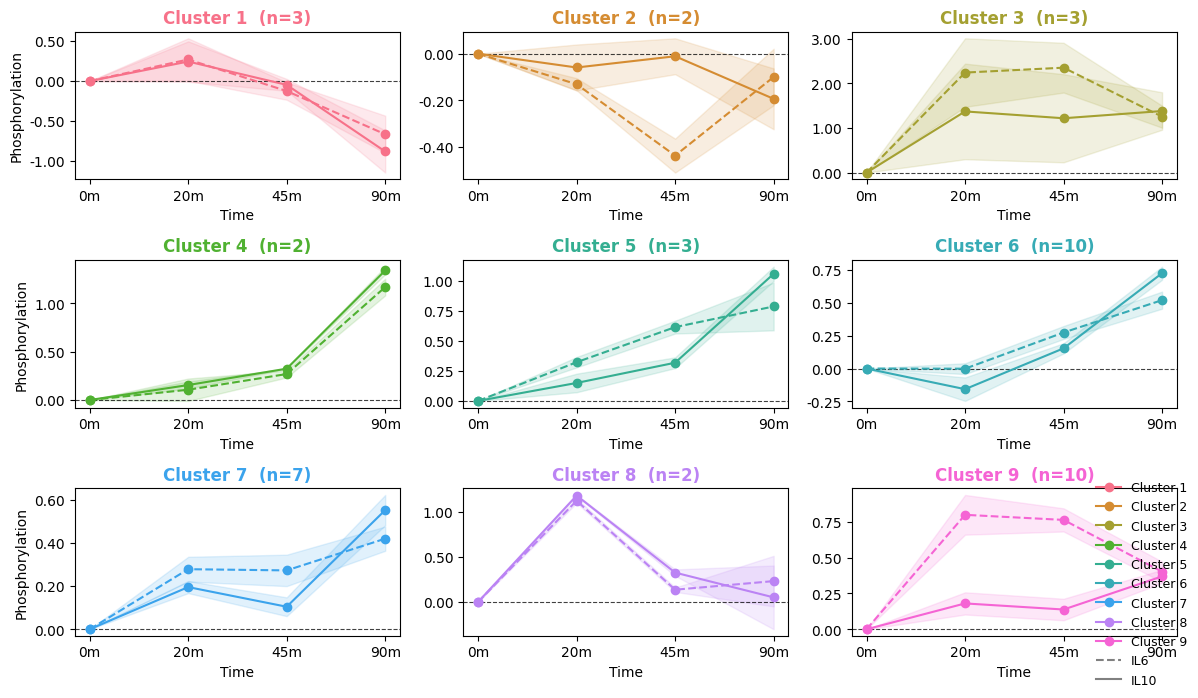

In [11]:
time_order = ["0m", "20m", "45m", "90m"]

# new file's column convention: uppercase IL6/IL10, PBS_0 for baseline,
# no "m" suffix on the timepoint numbers (was Unstim/il6/il10 with "20m"
# style suffixes in the old low-variance file)
unstim_cols = [c for c in prot_df.columns if "PBS_0" in c]
il6_cols    = [c for c in prot_df.columns if "IL6" in c]
il10_cols   = [c for c in prot_df.columns if "IL10" in c]

clusters = sorted(prot_df["cluster"].unique())
x = np.arange(len(time_order))

ncols = 3
nrows = int(np.ceil(len(clusters) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 7))
axes = axes.flatten()

for i, clus in enumerate(clusters):

    ax = axes[i]
    cluster_df = prot_df[prot_df["cluster"] == clus]
    color = cluster_df["cluster_color"].iloc[0]
    n = len(cluster_df)

    for cytokine, cols, linestyle in [("IL6", il6_cols, "--"), ("IL10", il10_cols, "-")]:

        means, sems = [], []

        for t in time_order:
            time_cols = unstim_cols if t == "0m" else [c for c in cols if t.rstrip("m") in c]
            per_site = cluster_df[time_cols].mean(axis=1)
            means.append(per_site.mean())
            sems.append(stats.sem(per_site))

        means = np.array(means)
        sems  = np.array(sems)

        ax.plot(x, means, marker="o", color=color, linestyle=linestyle, zorder=3)
        ax.fill_between(x, means - sems, means + sems, color=color, alpha=0.15, zorder=2)

    ax.set_xticks(x)
    ax.set_xticklabels(time_order)
    ax.set_title(f"Cluster {clus}  (n={n})", color=color, fontweight="bold")
    ax.set_xlabel("Time")
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.75)
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))  # force 2 decimal places on all subplots
    if i % ncols == 0:
        ax.set_ylabel("Phosphorylation")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

cluster_handles = [
    Line2D([0], [0], color=prot_df[prot_df["cluster"] == c]["cluster_color"].iloc[0],
           marker="o", linestyle="-", label=f"Cluster {c}")
    for c in clusters
]
style_handles = [
    Line2D([0], [0], color="gray", linestyle="--", label="IL6"),
    Line2D([0], [0], color="gray", linestyle="-",  label="IL10"),
]
fig.legend(handles=cluster_handles + style_handles, loc="lower right", fontsize=9, frameon=False)

plt.tight_layout()
plt.savefig(f"{out_dir}/figures/all_clusters_trajectory_panel.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{out_dir}/figures/all_clusters_trajectory_panel.svg", dpi=300, bbox_inches="tight")
plt.show()